# 06 · Anatomy of the shift

This notebook looks inside the trained SisFall models (seed 0) to separate two effects:

* **covariate shift**: Parkinsonian walking does not look like SisFall ADL to the network
  (measured with MMD and a domain-classifier probe on the embeddings);
* **concept shift**: the direction that separates FoG from walking is not the direction that
  separates falls from ADL (measured by the cosine between the two class-difference vectors).

It ends with the overview figure used in the paper and the poster.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.manifold import TSNE

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C
from src.engine import extract_embeddings
from src.experiment import load_all, load_scaler, sisfall_splits
from src.metrics import domain_classifier_auc, mmd_rbf
from src.models import build_model
from src.plotting import save, set_style

set_style()
X_sis, meta_sis, X_dap, meta_dap = load_all()
src_scaler, tgt_scaler = load_scaler("source"), load_scaler("target")
S = sisfall_splits(X_sis, meta_sis, src_scaler)
X_dom = tgt_scaler.transform(X_dap)
X_srcstat = src_scaler.transform(X_dap)
y_dap = meta_dap.label.values
best_hp = json.load(open(C.METRICS / "best_hparams.json"))

rng = np.random.default_rng(0)
yt = S["test"]["y"]


def sample(idx, n=3000):
    return rng.choice(idx, min(n, len(idx)), replace=False)


i_adl = sample(np.flatnonzero(yt == 0))
i_fall = np.flatnonzero(yt == 1)
i_walk = sample(np.flatnonzero(y_dap == 0))
i_fog = sample(np.flatnonzero(y_dap == 1))
print(len(i_adl), len(i_fall), len(i_walk), len(i_fog))

3000 381 3000 1734


In [2]:
def load_model(arch, seed=0):
    hp = dict(best_hp[arch])
    hp.pop("lr")
    m = build_model(arch, hp)
    m.load_state_dict(torch.load(C.MODELS_DIR / arch.replace("-", "").lower() / f"seed{seed}.pt",
                                 weights_only=False, map_location="cpu")["state_dict"])
    return m


def stat_feats(X):
    return np.hstack([X.mean(1), X.std(1), np.percentile(X, [5, 50, 95], axis=1).transpose(1, 0, 2).reshape(len(X), -1)])


EMB, rows = {}, []
spaces = {"input statistics": None, **{a: a for a in C.ARCHS}}
for name in spaces:
    if name == "input statistics":
        f = lambda X: stat_feats(X)
    else:
        model = load_model(name)
        f = lambda X, m=model: extract_embeddings(m, X)
    E = {"SisFall ADL": f(S["test"]["X"][i_adl]), "SisFall fall": f(S["test"]["X"][i_fall]),
         "Daphnet walk": f(X_dom[i_walk]), "Daphnet FoG": f(X_dom[i_fog]),
         "Daphnet walk (source stats)": f(X_srcstat[i_walk])}
    EMB[name] = E
    d_fall = E["SisFall fall"].mean(0) - E["SisFall ADL"].mean(0)
    d_fog = E["Daphnet FoG"].mean(0) - E["Daphnet walk"].mean(0)
    rows.append({
        "space": name,
        "MMD² ADL vs walk (domain stats)": mmd_rbf(E["SisFall ADL"], E["Daphnet walk"]),
        "MMD² ADL vs walk (source stats)": mmd_rbf(E["SisFall ADL"], E["Daphnet walk (source stats)"]),
        "domain probe AUROC (domain stats)": domain_classifier_auc(E["SisFall ADL"], E["Daphnet walk"]),
        "domain probe AUROC (source stats)": domain_classifier_auc(E["SisFall ADL"], E["Daphnet walk (source stats)"]),
        "cos(fall-ADL, FoG-walk)": float(d_fall @ d_fog / (np.linalg.norm(d_fall) * np.linalg.norm(d_fog))),
    })
shift = pd.DataFrame(rows).set_index("space")
shift.to_csv(C.METRICS / "shift_measures.csv")
shift.round(4)

,MMD² ADL vs walk (domain stats),MMD² ADL vs walk (source stats),domain probe AUROC (domain stats),domain probe AUROC (source stats),"cos(fall-ADL, FoG-walk)"
space,,,,,
input statistics,0.0720,0.1096,0.9946,0.9578,0.7657
CNN-1D,0.0809,0.1996,0.9955,0.9940,0.1816
LSTM,0.0167,0.4461,0.9753,0.9893,0.0955
GRU,0.0742,0.0968,0.9809,0.9930,-0.0298
Transformer,0.0236,0.1278,0.9620,0.9758,0.1224


A domain probe AUROC close to 1 means Parkinsonian walking and healthy ADL are trivially
separable in that space: covariate shift. A negative cosine means the network's "fall
direction" points away from FoG: concept shift, which no amount of input normalisation can fix.

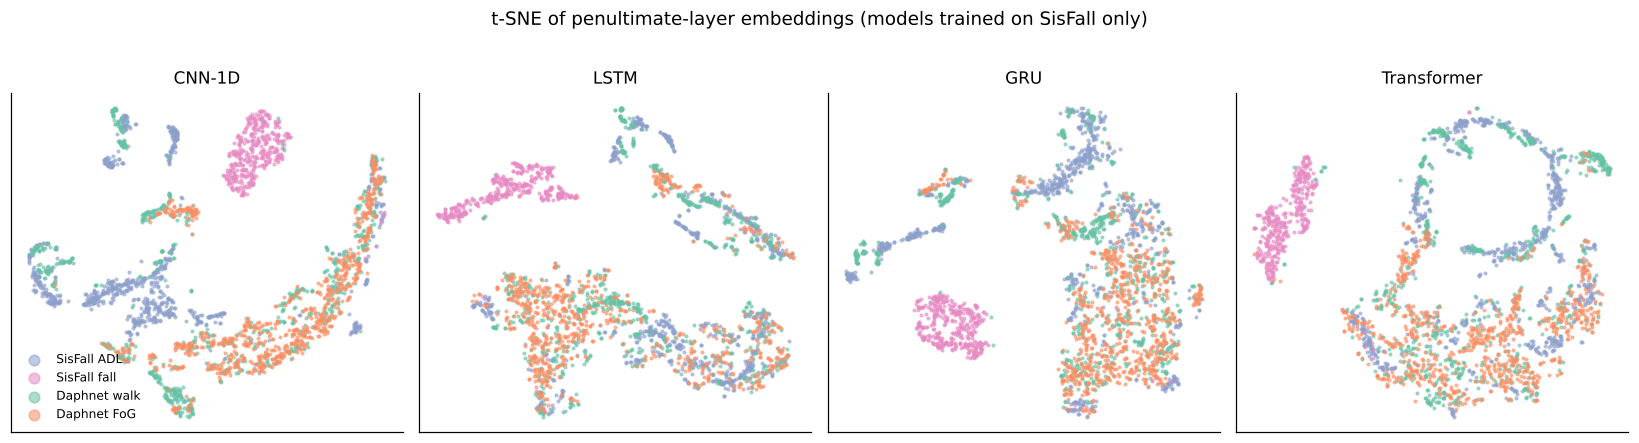

In [3]:
GCOL = {"SisFall ADL": "#8DA0CB", "SisFall fall": "#E78AC3", "Daphnet walk": "#66C2A5", "Daphnet FoG": "#FC8D62"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, arch in zip(axes, C.ARCHS):
    E = EMB[arch]
    keys = list(GCOL)
    sub = {k: E[k][rng.choice(len(E[k]), min(800, len(E[k])), replace=False)] for k in keys}
    Z = TSNE(2, perplexity=40, init="pca", random_state=0).fit_transform(np.vstack([sub[k] for k in keys]))
    o = 0
    for k in keys:
        n = len(sub[k])
        ax.scatter(*Z[o:o + n].T, s=3, alpha=0.55, color=GCOL[k], label=k)
        o += n
    ax.set_title(arch)
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(markerscale=4, frameon=False, fontsize=8, loc="best")
fig.suptitle("t-SNE of penultimate-layer embeddings (models trained on SisFall only)", y=1.02)
fig.tight_layout()
save(fig, "fig20_embedding_tsne")

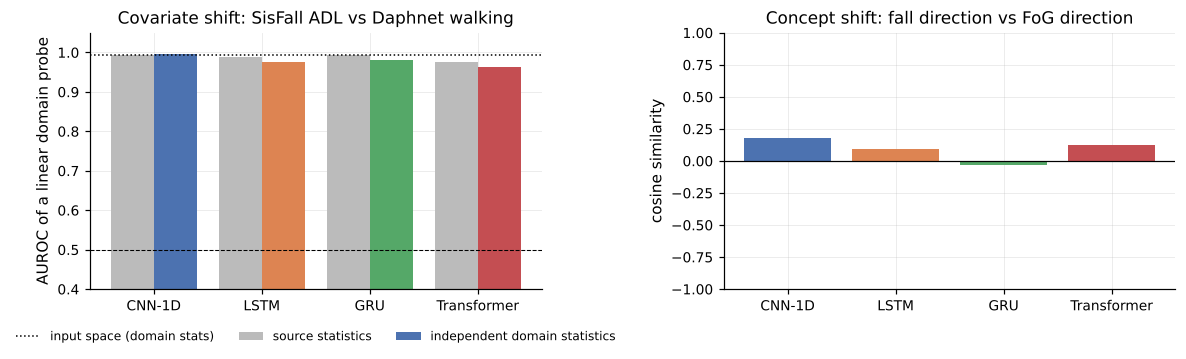

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
s = shift.loc[C.ARCHS]
x = np.arange(len(C.ARCHS))
axes[0].bar(x - 0.2, s["domain probe AUROC (source stats)"], 0.4, color="#BBBBBB", label="source statistics")
axes[0].bar(x + 0.2, s["domain probe AUROC (domain stats)"], 0.4, color=[C.PALETTE[a] for a in C.ARCHS],
            label="independent domain statistics")
axes[0].axhline(shift.loc["input statistics", "domain probe AUROC (domain stats)"], ls=":", c="k", lw=1,
                label="input space (domain stats)")
axes[0].axhline(0.5, ls="--", c="k", lw=0.7)
axes[0].set_xticks(x, C.ARCHS)
axes[0].set_ylim(0.4, 1.05)
axes[0].set_ylabel("AUROC of a linear domain probe")
axes[0].set_title("Covariate shift: SisFall ADL vs Daphnet walking")
axes[0].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
axes[1].bar(x, s["cos(fall-ADL, FoG-walk)"], color=[C.PALETTE[a] for a in C.ARCHS])
axes[1].axhline(0, c="k", lw=0.8)
axes[1].set_xticks(x, C.ARCHS)
axes[1].set_ylim(-1, 1)
axes[1].set_ylabel("cosine similarity")
axes[1].set_title("Concept shift: fall direction vs FoG direction")
fig.tight_layout()
save(fig, "fig21_shift_decomposition")

## Training-free references

Two single-number scores computed directly from each Daphnet window, with no learning at all:
the freeze index of Moore et al. (2008) on the trunk AP axis, and the standard deviation of
|a|, which is roughly what a fall detector keys on. They tell us what is achievable with zero
labels when the right physical prior is used.

In [5]:
from scipy import signal as sps
from sklearn.metrics import roc_auc_score

f, P = sps.welch(X_dap[:, :, 1] - X_dap[:, :, 1].mean(1, keepdims=True), fs=C.FS, nperseg=C.WIN, axis=-1)
freeze_index = np.log10((P[:, (f >= 3) & (f <= 8)].sum(1) + 1e-9) / (P[:, (f >= 0.5) & (f < 3)].sum(1) + 1e-9))
energy = X_dap[:, :, 3].std(1)
baselines = pd.DataFrame({
    "score": ["freeze index (trunk AP)", "|a| standard deviation"],
    "daphnet_auroc": [roc_auc_score(y_dap, freeze_index), roc_auc_score(y_dap, energy)],
})
baselines.to_csv(C.METRICS / "training_free_baselines.csv", index=False)
FI_AUROC = baselines.daphnet_auroc.iloc[0]
baselines.round(4)

,score,daphnet_auroc
0,freeze index (trunk AP),0.6626
1,|a| standard deviation,0.6825


## Overview: one AUROC per setting and architecture

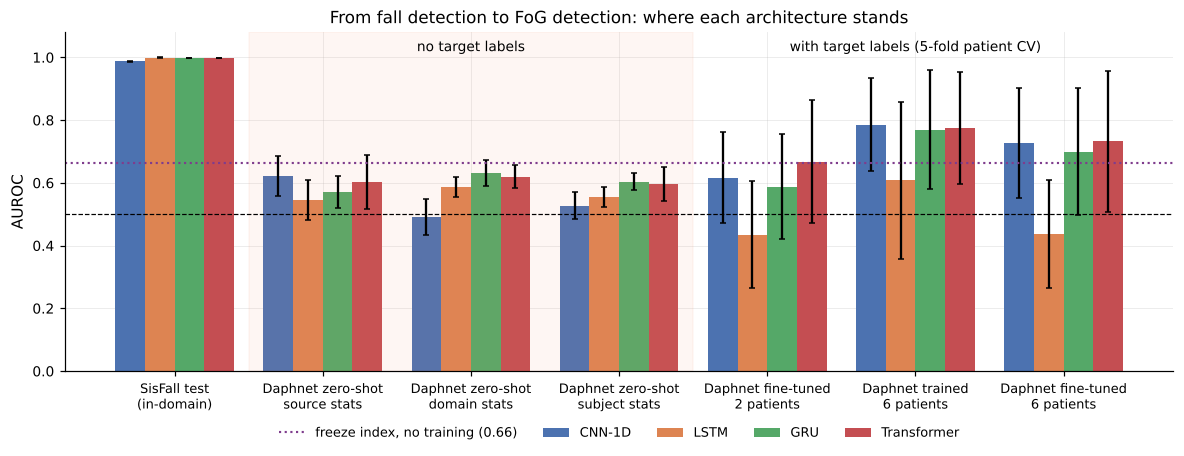

arch,CNN-1D,LSTM,GRU,Transformer
SisFall test (in-domain),0.987,0.999,0.999,0.998
Daphnet zero-shot source stats,0.621,0.547,0.571,0.603
Daphnet zero-shot domain stats,0.491,0.587,0.631,0.620
Daphnet zero-shot subject stats,0.528,0.554,0.604,0.596
Daphnet fine-tuned 2 patients,0.617,0.435,0.588,0.668
Daphnet trained 6 patients,0.786,0.608,0.769,0.776
Daphnet fine-tuned 6 patients,0.727,0.437,0.700,0.732


In [6]:
test_seed = pd.read_csv(C.METRICS / "sisfall_test_per_seed.csv")
zs_seed = pd.read_csv(C.METRICS / "daphnet_zero_shot_per_seed.csv")
adapt = pd.read_csv(C.METRICS / "target_adaptation_per_fold.csv")
SETTINGS = [
    ("SisFall test\n(in-domain)", test_seed.groupby("arch").auroc),
    ("Daphnet zero-shot\nsource stats", zs_seed[zs_seed.normalisation == "source statistics"].groupby("arch").auroc),
    ("Daphnet zero-shot\ndomain stats", zs_seed[zs_seed.normalisation == "domain statistics"].groupby("arch").auroc),
    ("Daphnet zero-shot\nsubject stats", zs_seed[zs_seed.normalisation == "subject statistics"].groupby("arch").auroc),
    ("Daphnet fine-tuned\n2 patients", adapt[adapt.condition == "SisFall pre-trained · 2 patients"].groupby("arch").auroc),
    ("Daphnet trained\n6 patients", adapt[adapt.condition == "scratch · 6 patients"].groupby("arch").auroc),
    ("Daphnet fine-tuned\n6 patients", adapt[adapt.condition == "SisFall pre-trained · 6 patients"].groupby("arch").auroc),
]
fig, ax = plt.subplots(figsize=(13, 4))
overview = {}
for j, (name, g) in enumerate(SETTINGS):
    mu, sd = g.mean().reindex(C.ARCHS), g.std().reindex(C.ARCHS)
    overview[name.replace("\n", " ")] = mu
    for i, arch in enumerate(C.ARCHS):
        ax.bar(j + (i - 1.5) * 0.2, mu[arch], 0.2, yerr=sd[arch], capsize=2, color=C.PALETTE[arch],
               label=arch if j == 0 else None)
ax.axhline(0.5, ls="--", c="k", lw=0.8)
ax.axhline(FI_AUROC, ls=":", c="#7F3C8D", lw=1.4, label=f"freeze index, no training ({FI_AUROC:.2f})")
ax.axvspan(0.5, 3.5, color="#FC8D62", alpha=0.07)
ax.text(2, 1.02, "no target labels", ha="center", fontsize=9)
ax.text(5, 1.02, "with target labels (5-fold patient CV)", ha="center", fontsize=9)
ax.set_xticks(range(len(SETTINGS)), [s[0] for s in SETTINGS], fontsize=8.5)
ax.set_ylabel("AUROC")
ax.set_ylim(0, 1.08)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=8.5)
ax.set_title("From fall detection to FoG detection: where each architecture stands")
save(fig, "fig22_overview_auroc")
overview = pd.DataFrame(overview).T
overview.to_csv(C.METRICS / "overview_auroc.csv")
overview.round(3)

In [7]:
oracle = pd.read_csv(C.METRICS / "hparam_oracle_selection.csv")
search = pd.read_csv(C.METRICS / "hparam_search.csv")
search["val_auprc_r"] = search.val_auprc.round(3)
sel = (search.sort_values(["val_auprc_r", "val_loss"], ascending=[False, True])
       .groupby("arch").head(1)[["arch", "daphnet_auroc_oracle_only"]])
cmp = sel.merge(oracle[["arch", "daphnet_auroc_oracle_only"]], on="arch", suffixes=(" (source-val selection)", " (oracle selection)"))
cmp.to_csv(C.METRICS / "selection_vs_oracle.csv", index=False)
cmp.round(4)

,arch,daphnet_auroc_oracle_only (source-val selection),daphnet_auroc_oracle_only (oracle selection)
0,Transformer,0.6565,0.6565
1,CNN-1D,0.5413,0.6875
2,GRU,0.6536,0.6536
3,LSTM,0.5138,0.5244
